# Real optical homodyne tomography: from ADC shots to a complex state and signed phase-space field

## 1. Problem

This Notebook actively reconstructs the complete selected real experiment. Three photon-number detectors each report three photons. A balanced homodyne detector then measures many phase-dependent quadratures of that conditional optical mode. The unknown is a full complex density matrix in photon states zero through thirty, together with its two-dimensional Wigner field. The latter is a signed canonical phase-space density, not a photograph or a positive intensity map.

The experimental source is *Integrated photonic source of Gottesman–Kitaev–Preskill qubits*, Nature642,587–591(2025), DOI10.1038/s41586-025-09044-5. The inverse uses the explicit list-mode positive maximum-likelihood method of A.I.Lvovsky, J.Opt.B6,S556–S559(2004), DOI10.1088/1464-4266/6/6/014, as actually implemented in the2025 author analysis. The primary comparison below is a separately executed unchanged original run on these exact raw measurements. Historical cached release states are shown only in the last figure and are never loaded as observations, truth or fresh answers.

There is no exact experimental state truth. Numerical agreement with the method reference must be distinguished from preparation fidelity or an independently known physical state.


In [1]:
from pathlib import Path
import os, sys, json, time, subprocess
import numpy as np
import scipy, matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path.cwd().resolve()
for _ in range(5):
    if (ROOT/'src').is_dir() and (ROOT/'data/raw_data.npz').is_file(): break
    ROOT=ROOT.parent
assert (ROOT/'src').is_dir()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations, calibrate
from src.physics_model import wigner_function,Q_GRID,P_GRID
from src.solvers import maximum_likelihood
from src.visualization import make_figures,state_statistics
FIGURE_DIR=Path(os.environ.get('IMAGING_FIGURE_DIR',str(ROOT.parents[1].parent/'imaging-101-maintainer/research_batch7_20261022/groups/physics_materials/xanadu/figures')))
print('Actual kernel executable:',sys.executable)
print('Python:',sys.version)
print('NumPy/SciPy/Matplotlib:',np.__version__,scipy.__version__,matplotlib.__version__)
print('Thread settings:',{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']})


Actual kernel executable: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
Python: 3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]
NumPy/SciPy/Matplotlib: 2.4.6 1.17.1 3.11.1
Thread settings: {'OMP_NUM_THREADS': '1', 'OPENBLAS_NUM_THREADS': '1', 'MKL_NUM_THREADS': '1'}


## 2. Data

The public NPZ is a lossless non-object extraction of the333 condition from all100 original acquisition files in chronological timestamp order. It contains3,756,232 real ADC readings, phase indices, detector confidence distances and independent blockwise offsets/vacuum/unconditional variance scans. These are existing measurements, not newly simulated quadratures. A separate raw-data redistribution license was not identified; the author publicly offers them for research and this is a local research package.

For block f, let s be its ADC value, mu its measured offset and V its64 phase-resolved vacuum variances. Canonical quadrature is q=(s−mu)/sqrt(2 mean(V)), so vacuum variance is1/2. Raw phase is its stored index times the block's phase increment. Phase calibration fits the unconditional signal-to-vacuum variance ratio; no reconstructed conditional state is involved. The native201-bin80% per-detector confidence procedure produces the three public strict cutoffs. The simultaneous three-detector selection defines1,881,028 accepted samples. Accepted values outside[-7,7] still enter every inverse update; that interval only defines the output Wigner window.


In [2]:
data=load_observations()
calibration=calibrate(data)
with np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as z:
    upstream={k:z[k].copy() for k in z.files}
with np.load(ROOT/'notebooks/reference_outputs/historical_context.npz',allow_pickle=False) as z:
    historical={k:z[k].copy() for k in z.files}
print('Raw / accepted samples:',len(calibration['q']),len(calibration['q_accepted']))
print('Actual confidence cutoffs:',calibration['cutoff'])
print('Accepted quadrature range:',calibration['q_accepted'].min(),calibration['q_accepted'].max())
print('Independent original phase-calibration max difference:',np.max(abs(calibration['phase_fit_param']-upstream['phase_fit_param'])))
assert len(calibration['q_accepted'])==1881028


Raw / accepted samples: 3756232 1881028
Actual confidence cutoffs: [5554.37313433 5811.44278607 7281.3880597 ]
Accepted quadrature range: -8.715152170549324 8.232550489805682
Independent original phase-calibration max difference: 0.0


## 3. Physics

Use dimensionless canonical position Q and momentum P with [Q,P]=i. For photon number n, the normalized oscillator wavefunction and phase-sensitive measurement amplitude are

$$\psi_n(q)=\frac{H_n(q)e^{-q^2/2}}{\pi^{1/4}\sqrt{2^n n!}},\qquad A_n(q,\theta)=e^{in\theta}\psi_n(q),\qquad p(q|\theta,\rho)=\mathbf A^\dagger\rho\mathbf A.$$

Here H is the physicists' Hermite polynomial, q is a measured quadrature, theta is calibrated local-oscillator phase, rho is the density and dagger denotes complex conjugate transpose. Its diagonal gives photon populations; off-diagonal complex elements carry coherence. The Born quantity p is a continuous probability density. The2004 paper uses canonical commutator i/2; its coordinate is native q/sqrt(2). Mixing these conventions would introduce a real physical scale error.

The calibrated phase is theta=x−b+a sin(x−c), where x is raw phase and b,a,c are block-specific nuisance parameters. Their independent variance fit is u cos²(theta)+v sin²(theta), with u,v fitted variance extrema.

The Wigner field is the transform of this same full complex density:

$$W(Q,P)=\frac{1}{\pi}\int e^{2iPy}\langle Q-y|\rho|Q+y\rangle\,dy.$$

The integral is over real y. Rows are P, columns Q. Full-plane normalization is one, but no finite-window renormalization is applied. Negative Wigner values are physically meaningful. The runtime recurrence and the Judge's independent generalized-Laguerre basis give separate implementations of this transform. Analytic vacuum, single-photon and complex coherent states verify normalization, negativity and momentum-axis sign.

## 4. Method

For each accepted shot k, the explicit Hermite recurrence constructs its31-dimensional vector A. Start with identity/31, compute the old-state Born probabilities, then apply the native update

$$R=\sum_k\frac{\mathbf A_k\mathbf A_k^\dagger}{\mathbf A_k^\dagger\rho\mathbf A_k},\qquad \rho^{new}=\frac{R\rho R}{\mathrm{Tr}(R\rho R)}.$$

Both R and the updated density are Hermitian-symmetrized exactly as in source. All accepted shots enter all100 updates. No histogram inversion, shot cap, generic solver, detector-loss correction or fitted phase rotation replaces this path. The stored likelihood uses the probabilities immediately before each update; the returned density includes that update. The fixed100-step budget is not renamed a proven global optimum.

The following cell performs the primary full reconstruction now. It does not load the CLI measurement or a historical state as an initializer.


In [3]:
primary_start=time.perf_counter()
fresh=maximum_likelihood(calibration['q_accepted'],calibration['phi_accepted'])
fresh['wigner']=wigner_function(fresh['density_matrix'],Q_GRID,P_GRID)
primary_seconds=time.perf_counter()-primary_start
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',density_matrix=fresh['density_matrix'][None],wigner=fresh['wigner'][None])
arrays={k:v for k,v in fresh.items() if isinstance(v,np.ndarray)}
arrays.update({f'rho_step_{k}':v for k,v in fresh['snapshots'].items()})
arrays.update({k:calibration[k] for k in ['phase_fit_param','cutoff','accepted_indices','q_accepted','phi_accepted']})
arrays.update(iterations=np.array(fresh['iterations']),runtime_seconds=np.array(fresh['runtime_seconds']))
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh.npz',**arrays)
print('Actual full primary reconstruction seconds:',primary_seconds)
print('Density max difference from independently reproduced original:',np.max(abs(fresh['density_matrix']-upstream['density_matrix'][0])))
print('Wigner max difference:',np.max(abs(fresh['wigner']-upstream['wigner'][0])))
print('Physical state statistics:',json.dumps(state_statistics(fresh['density_matrix'],fresh['wigner']),indent=2))


Actual full primary reconstruction seconds: 320.3903505000053
Density max difference from independently reproduced original: 0.0
Wigner max difference: 0.0
Physical state statistics: {
  "purity": 0.13480325332724466,
  "negative_volume_finite_window": 0.024173876171459618,
  "wigner_integral_finite_window": 0.9990877567121863,
  "stabilizer_p": 0.2729577290397686,
  "stabilizer_q": 0.24665200159320558,
  "minimum_eigenvalue": -6.305006980114358e-18
}


## 5. Results and scientific comparisons

The experiments below are also fresh inversions. Photon cutoffs10 and20 retain all accepted shots but change represented photon support. The raw-phase ablation keeps the full31-state representation and all accepted shots while omitting the independent phase correction. Each uses100 updates. They are sensitivity controls, not alternate unknowns counted as new tasks. Their density/Wigner discrepancies are explicitly against the native method reference, not an unknown experimental truth.

The six figure groups preserve the author Notebook's measured calibration, phase fitting, confidence histograms, quadrature distributions, ML diagnostics, full density/Wigner/marginals, cached state comparisons and stabilizer observables. Additional photon-support and phase-calibration controls expose model sensitivity. Historical111/133/335/444/333 cached states appear separately, with their original numerical cells actually executed for provenance; their acquisition/iteration details are not independently certified and no raw-data reconstruction is claimed for those historical contexts.


In [4]:
comparisons={}
comparison_start=time.perf_counter()
for cutoff in (10,20):
    label=f'Cutoff {cutoff}'
    result=maximum_likelihood(calibration['q_accepted'],calibration['phi_accepted'],cutoff=cutoff)
    result['wigner']=wigner_function(result['density_matrix'],Q_GRID,P_GRID)
    comparisons[label]=result
    print(label,'actual seconds',result['runtime_seconds'],flush=True)
result=maximum_likelihood(calibration['q_accepted'],calibration['uncorrected_phi_accepted'])
result['wigner']=wigner_function(result['density_matrix'],Q_GRID,P_GRID)
comparisons['Uncorrected phase']=result
print('Uncorrected phase actual seconds:',result['runtime_seconds'])
comparison_arrays={}
for label,result in comparisons.items():
    for key,value in result.items():
        if isinstance(value,np.ndarray):comparison_arrays[label.replace(' ','_')+'_'+key]=value
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_comparisons.npz',**comparison_arrays)
print('All comparison elapsed seconds:',time.perf_counter()-comparison_start)


Cutoff 10 actual seconds 106.1059699000034


Cutoff 20 actual seconds 218.29264450000483


Uncorrected phase actual seconds: 320.4230629999947
All comparison elapsed seconds: 645.2979534000042


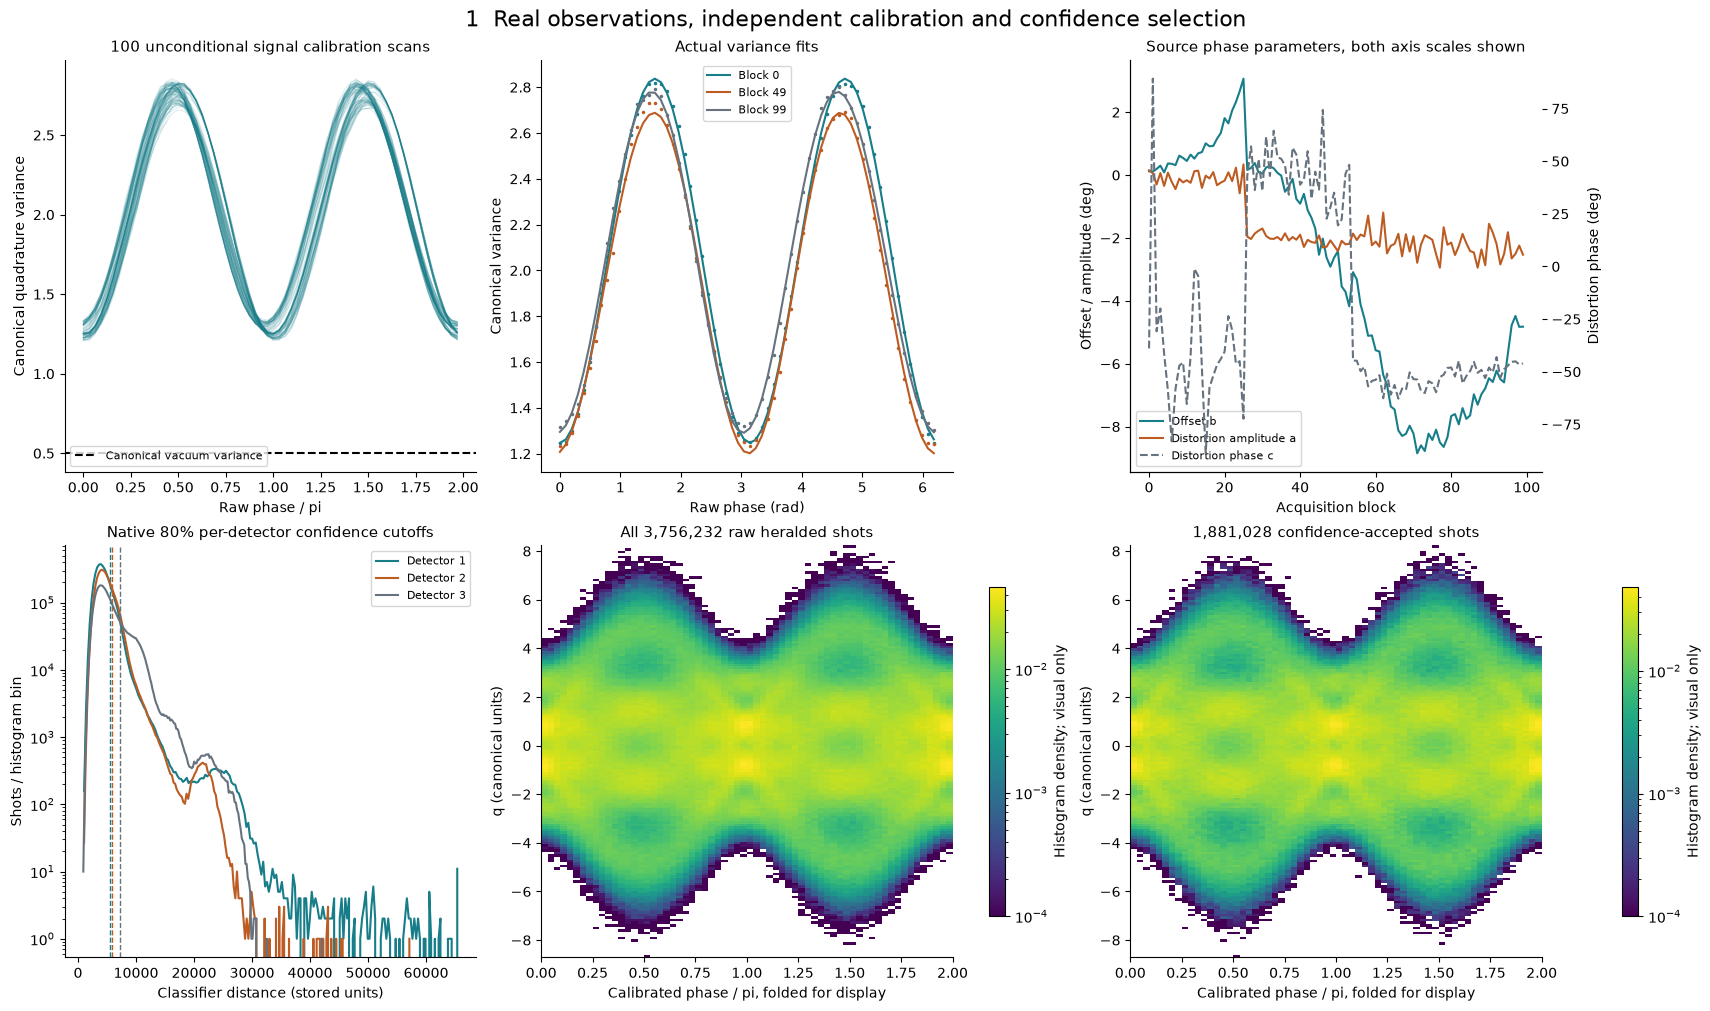

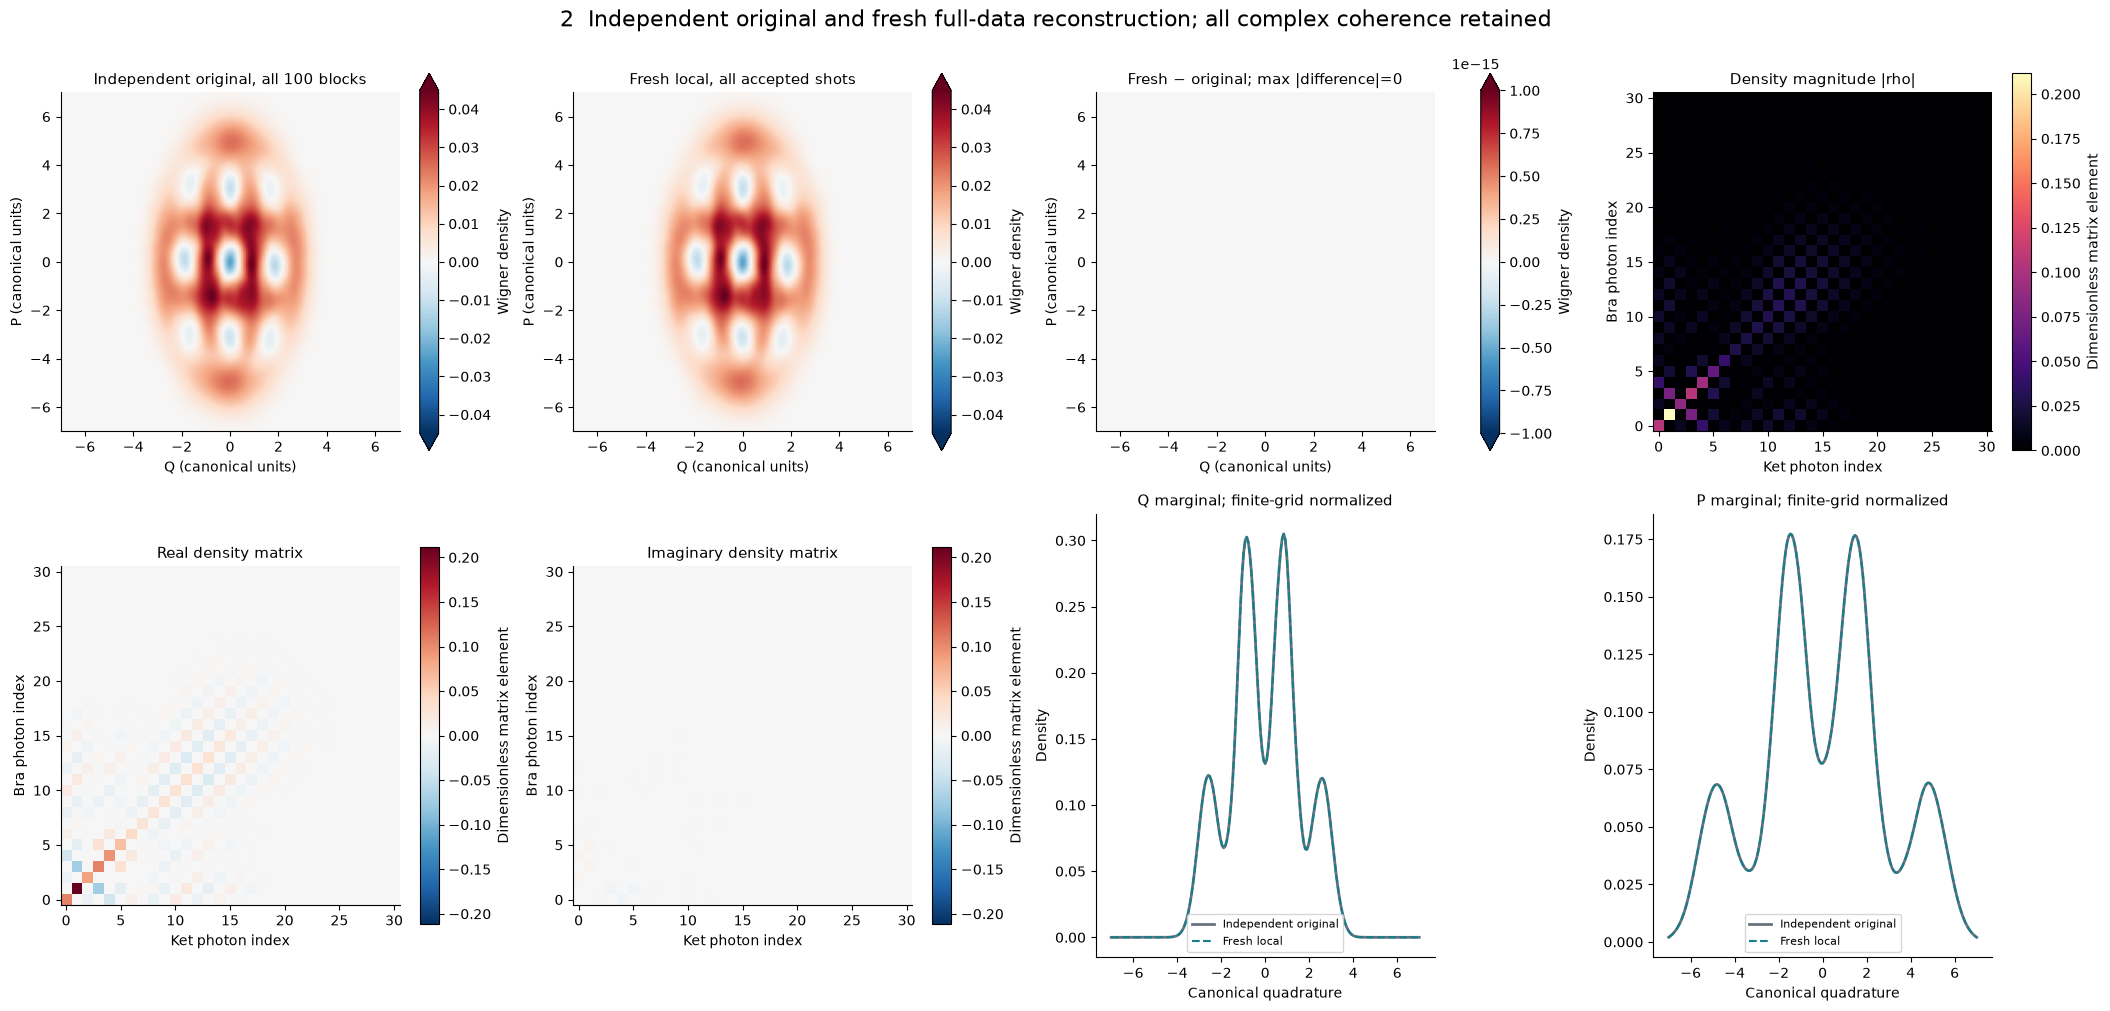

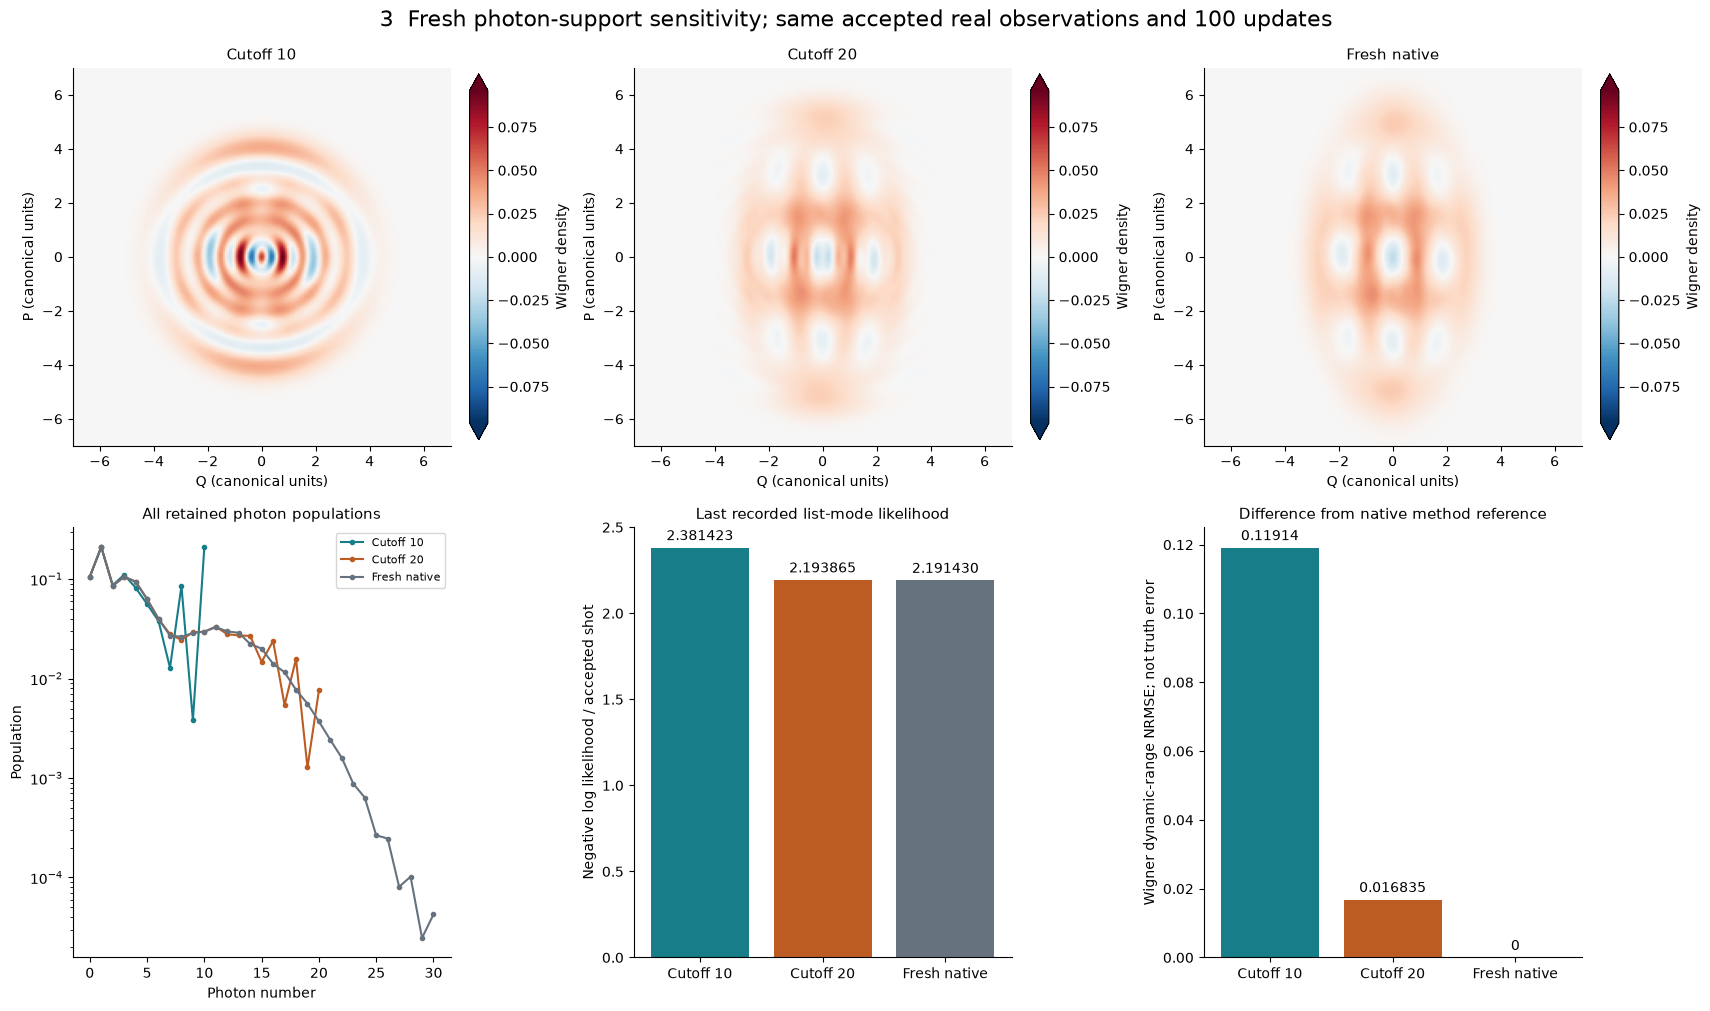

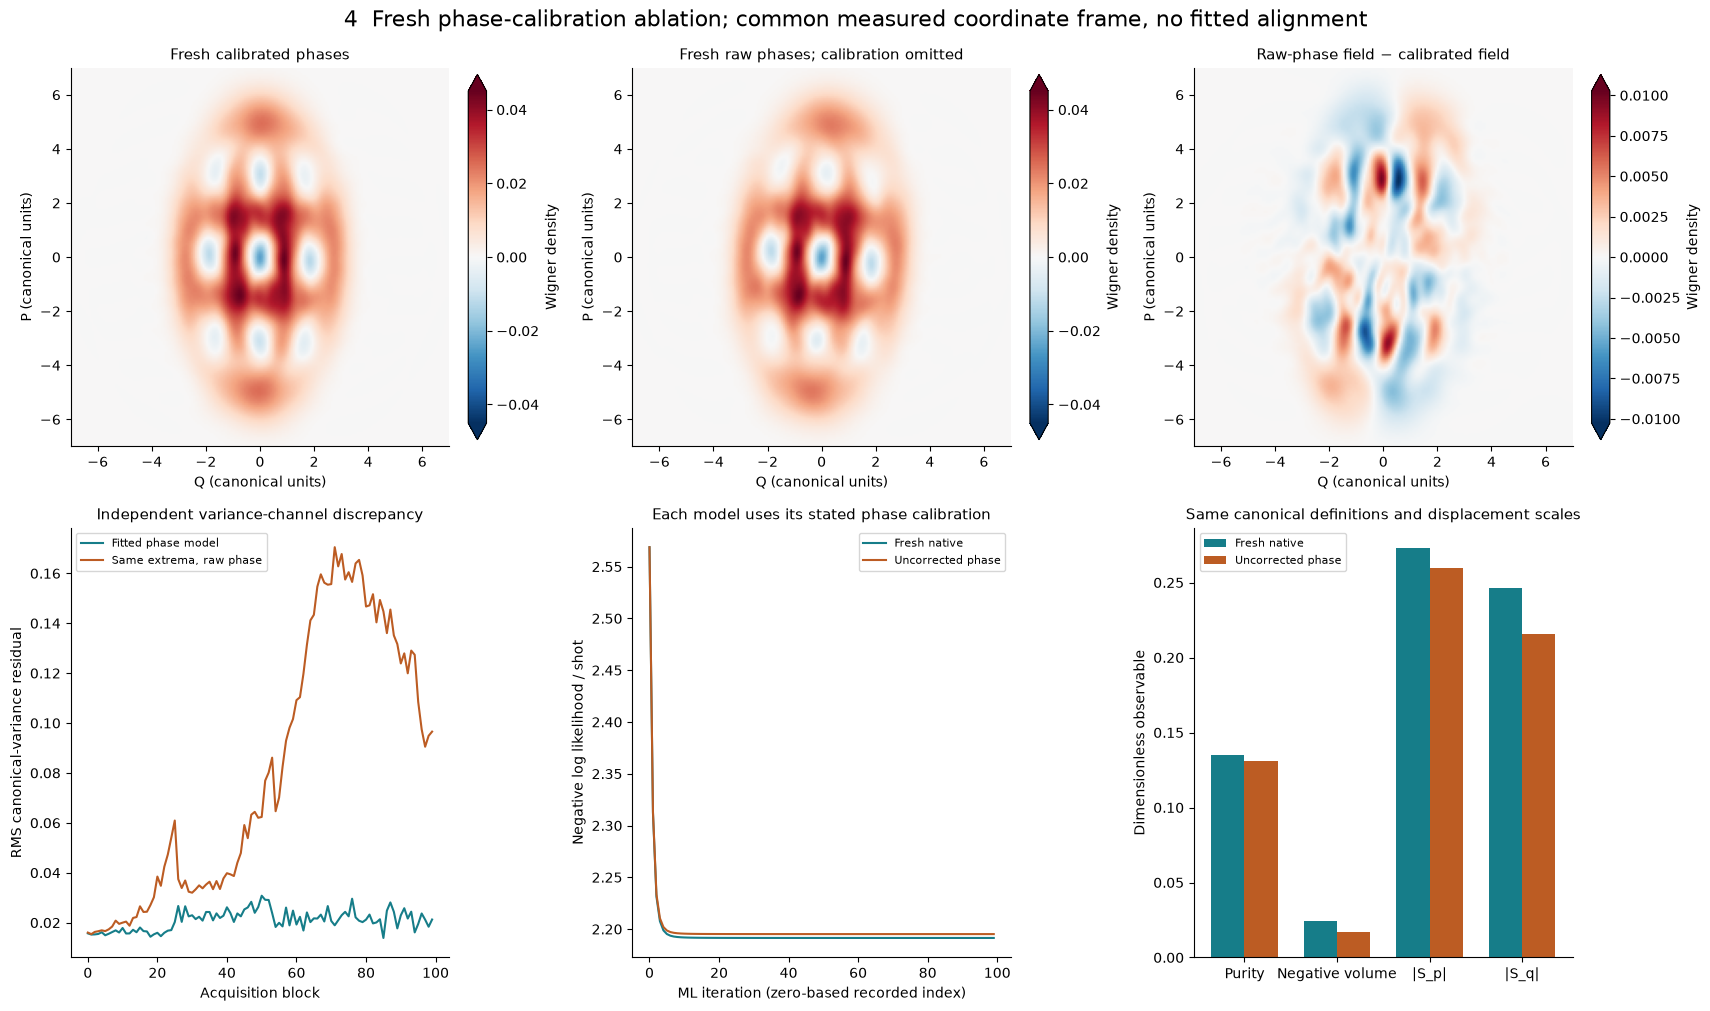

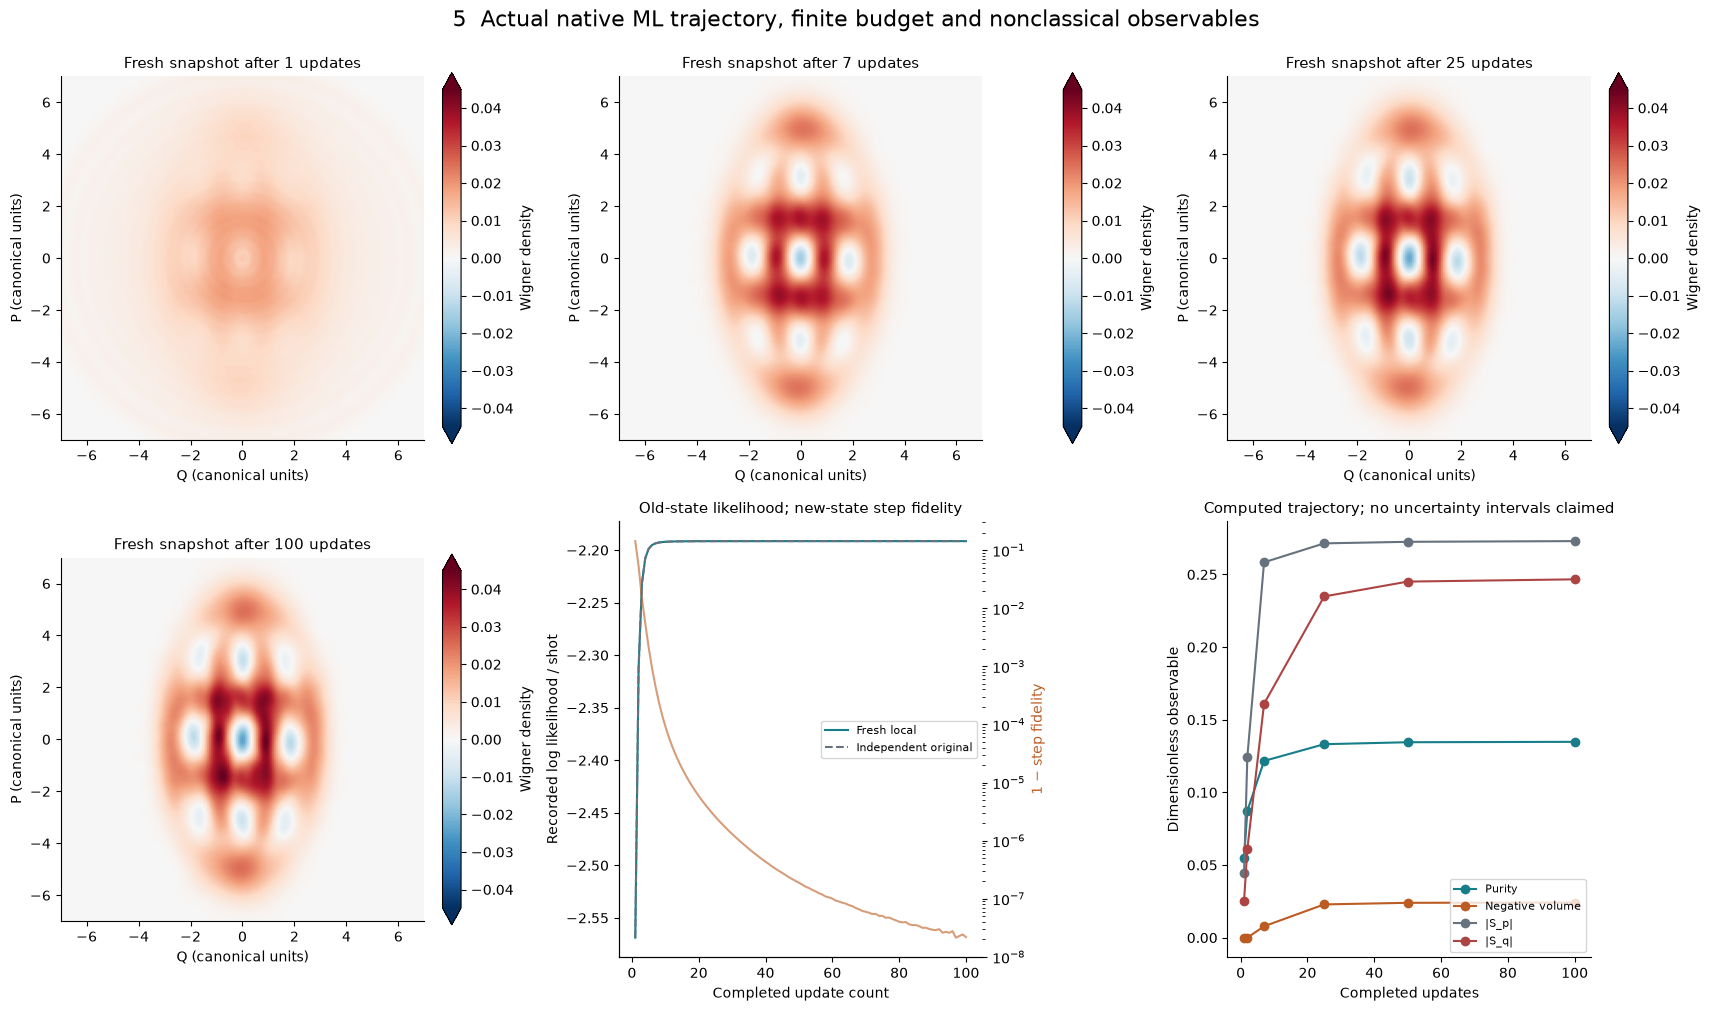

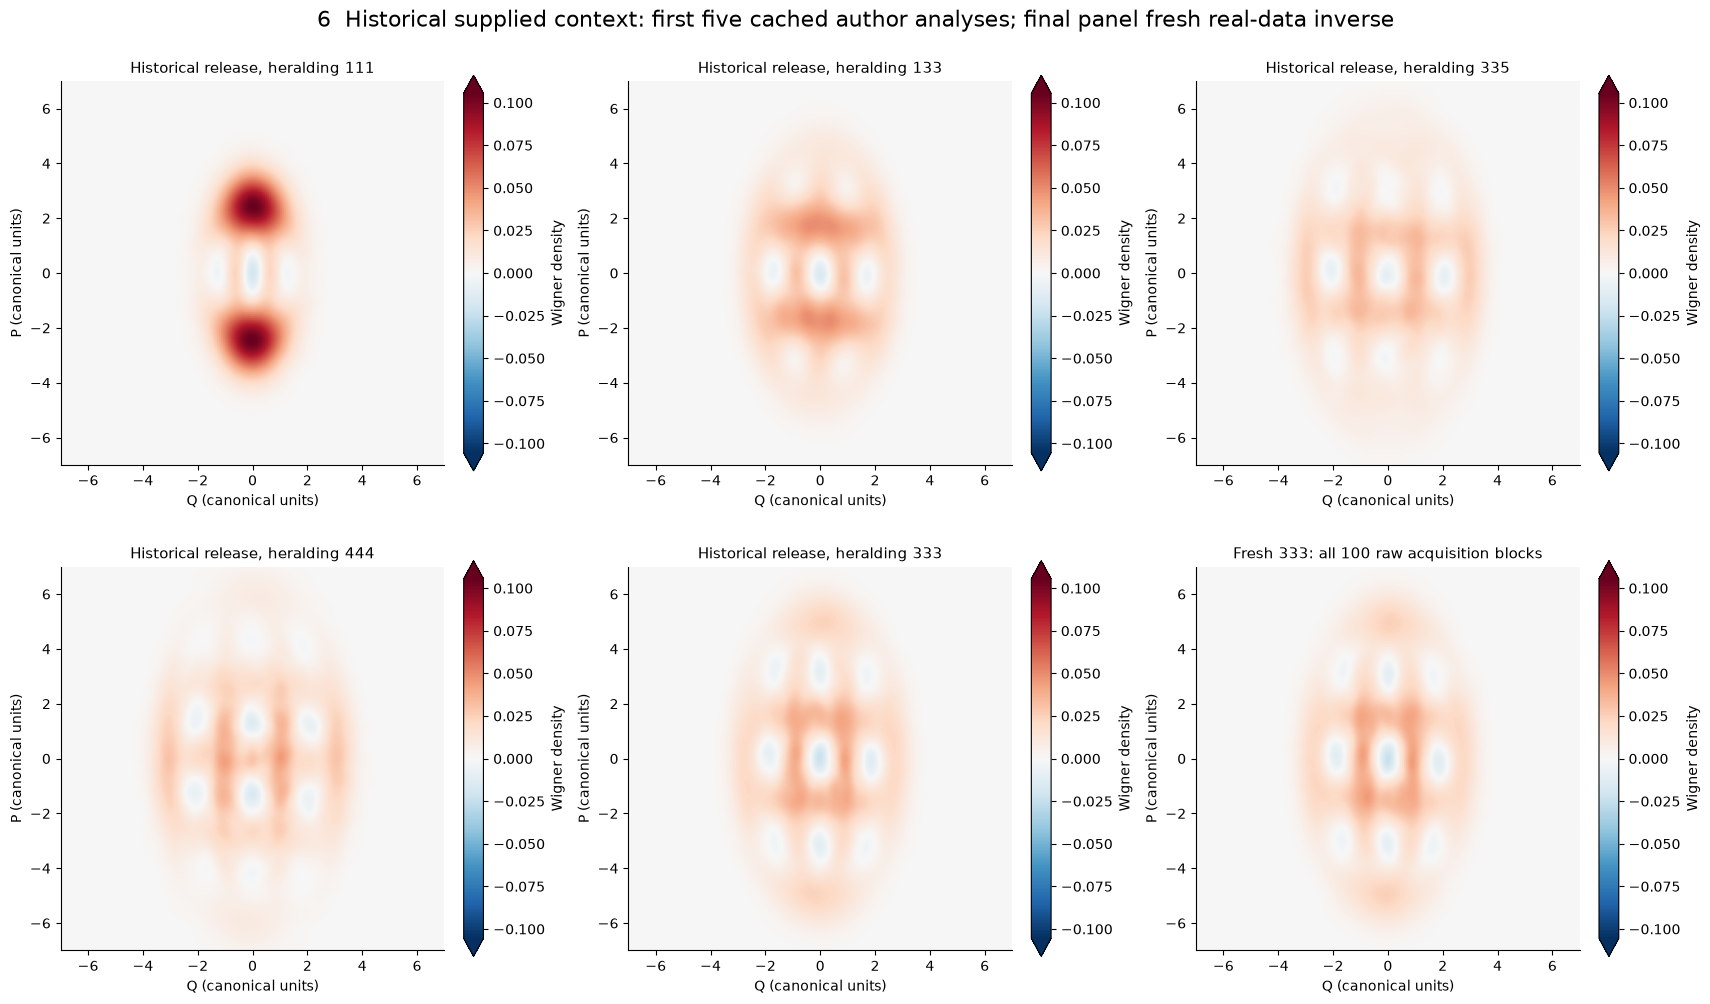

Every plotted fresh method was computed above. Historical cached context remains separately labeled.
{
  "Fresh native": {
    "density_relative_l2_vs_native_reference": 0.0,
    "wigner_dynamic_range_nrmse_vs_native_reference": 0.0,
    "last_recorded_negative_loglikelihood_per_shot": 2.1914296334224534,
    "purity": 0.13480325332724466,
    "negative_volume_finite_window": 0.024173876171459618,
    "wigner_integral_finite_window": 0.9990877567121863,
    "stabilizer_p": 0.2729577290397686,
    "stabilizer_q": 0.24665200159320558,
    "minimum_eigenvalue": -6.305006980114358e-18
  },
  "Cutoff 10": {
    "density_relative_l2_vs_native_reference": 0.7920876915808402,
    "wigner_dynamic_range_nrmse_vs_native_reference": 0.11914320055294432,
    "last_recorded_negative_loglikelihood_per_shot": 2.381423270947684,
    "purity": 0.1926756628269215,
    "negative_volume_finite_window": 0.10080552522723128,
    "wigner_integral_finite_window": 0.99999999987656,
    "stabilizer_p": 0.1314696

Standalone Judge actual returncode: 0
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "rho_relative_l2": 0.0,
    "wigner_nrmse": 0.0,
    "rho_hermitian_relative": 0.0,
    "rho_trace_error": 1.1102230246251565e-16,
    "rho_minimum_eigenvalue": -6.305006980114358e-18,
    "wigner_density_consistency_maxabs": 1.214306433183765e-16
  },
  "thresholds": {
    "rho_relative_l2": {
      "comparison": "less_equal",
      "boundary": 1e-06
    },
    "wigner_nrmse": {
      "comparison": "less_equal",
      "boundary": 1e-07
    },
    "rho_hermitian_relative": {
      "comparison": "less_equal",
      "boundary": 1e-06
    },
    "rho_trace_error": {
      "comparison": "less_equal",
      "boundary": 1e-06
    },
    "rho_minimum_eigenvalue": {
      "comparison": "greater_equal",
      "boundary": -1e-06
    },
    "wigner_density_consistency_maxabs": {
      "comparison": "less_equal",
      "boundary": 1e-06
    }
  },
  "errors": []
}


In [5]:
figures,measurements=make_figures(data,calibration,upstream,fresh,comparisons,historical,directory=FIGURE_DIR)
for figure in figures:
    display(figure)
    plt.close(figure)
print('Every plotted fresh method was computed above. Historical cached context remains separately labeled.')
print(json.dumps({k:measurements[k] for k in ['Fresh native','Cutoff 10','Cutoff 20','Uncorrected phase']},indent=2))
command=[sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')]
judged=subprocess.run(command,cwd=ROOT,capture_output=True,text=True,shell=False)
print('Standalone Judge actual returncode:',judged.returncode)
print((ROOT/'output/judge_report.json').read_text())
assert judged.returncode==0,judged.stderr


## 6. Conclusion

The complete measured conditional ensemble is reconstructed with local explicit mathematics, including its complex coherence and signed phase-space field. Independent original reproduction, analytic physical cases and the standalone Judge are distinct pieces of evidence. Passing numerical method agreement does not create an experimentally known state truth.

The finite photon support, fitted phase distortion, confidence postselection and finite ML budget affect the result. The sensitivity controls display these effects in the same canonical coordinate frame, without a fitted alignment or gain. The effective state includes detection losses; no unprovided inverse loss channel is introduced. The finite Wigner window may omit tails and is never independently normalized. Step-fidelity stability is a numerical diagnostic, not a bootstrap confidence interval or a certified preparation fidelity. Historical supplied state patterns retain their separate provenance.

PNG/SVG/PDF figures, actual numerical plot sources and full-precision method metrics are exported to the private maintainer figure directory. The submission contains both required outputs and is graded as such.
